# EduQuest — Random Forest pe datele din CSV


## 1. Importăm bibliotecile


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEED = 42
import re


## 2. Citim fișierul CSV


In [2]:
filename = "EduQuest_Dataset_Cu_Raspunsuri_Chestionare(2).csv"
if not Path(filename).exists():
    fisiere = sorted(Path('.').glob('EduQuest_Dataset_Cu_Raspunsuri_Chestionare*.csv'))
    if not fisiere:
        raise FileNotFoundError("Nu găsesc CSV-ul EduQuest. Pune-l lângă notebook.")
    filename = str(fisiere[-1])

df = pd.read_csv(filename)
df.columns = df.columns.str.strip()
print('Fișier:', filename)
print('Dimensiuni:', df.shape)
display(df.head())


Fișier: EduQuest_Dataset_Cu_Raspunsuri_Chestionare.csv
Dimensiuni: (300, 88)


,StudentID,Grup_AI,Scor_EscapeCode,Raspunsuri_corecte_EscapeCode,Raspunsuri_gresite_EscapeCode,Total_raspunsuri_EscapeCode,Greseli_EscapeCode,Timp_EscapeCode_min,Incercari_EscapeCode,Indicii_EscapeCode,...,Interes_invatare_Q3_final,Interes_invatare_Q4_final,Autoeficacitate_Q1_initial,Autoeficacitate_Q2_initial,Autoeficacitate_Q3_initial,Autoeficacitate_Q4_initial,Autoeficacitate_Q1_final,Autoeficacitate_Q2_final,Autoeficacitate_Q3_final,Autoeficacitate_Q4_final
0,1,0,28,2,8,10,8,23,3,0,...,1,3,1,1,1,1,4,2,1,5
1,2,0,96,4,6,10,6,53,9,0,...,1,1,1,1,1,1,2,2,1,3
2,3,1,68,4,8,12,8,17,6,1,...,5,5,5,5,5,5,5,5,5,5
3,4,1,93,4,3,7,3,32,9,0,...,1,1,1,1,1,1,3,1,1,3
4,5,0,54,3,3,6,3,32,8,0,...,1,1,5,4,2,5,5,5,5,5


## 3. Curățarea și validarea datelor


In [3]:
df = df.copy()
randuri_initiale = len(df)
df = df.drop_duplicates().copy()
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].astype('string').str.strip().replace({'': pd.NA, 'nan': pd.NA, 'None': pd.NA, 'NULL': pd.NA})

coloane_chestionar = [c for c in df.columns if re.search(r'_Q[1-4]_(initial|final)$', c)]
coloane_numerice = [c for c in df.columns if c.startswith(('Scor_', 'Raspunsuri_corecte_', 'Raspunsuri_gresite_', 'Total_raspunsuri_', 'Greseli_', 'Incercari_', 'Indicii_', 'Timp_')) or c in ['Test_initial', 'Test_final', 'Grup_AI', 'Delta_performanta', 'Delta_motivatie'] or c in coloane_chestionar]
for col in coloane_numerice:
    df[col] = pd.to_numeric(df[col], errors='coerce')

for col in coloane_chestionar:
    df.loc[~df[col].between(1, 5) | (df[col] % 1 != 0), col] = np.nan

for col in coloane_numerice:
    if col.startswith(('Scor_', 'Raspunsuri_corecte_', 'Raspunsuri_gresite_', 'Total_raspunsuri_', 'Greseli_', 'Incercari_', 'Indicii_', 'Timp_')):
        df.loc[df[col] < 0, col] = np.nan
if 'Grup_AI' in df:
    df.loc[~df['Grup_AI'].isin([0, 1]), 'Grup_AI'] = np.nan

if 'StudentID' in df:
    df = df.dropna(subset=['StudentID']).copy()
    duplicati_id = df['StudentID'].duplicated().sum()
    print('ID-uri repetate (de verificat manual):', duplicati_id)

print('Rânduri inițiale:', randuri_initiale)
print('Duplicate identice eliminate:', randuri_initiale - len(df))
print('Rânduri după curățare:', len(df))
print('Valori lipsă rămase:', int(df.isna().sum().sum()))
display(df.isna().sum().loc[lambda x: x > 0].sort_values(ascending=False))
display(df.head())


ID-uri repetate (de verificat manual): 0
Rânduri inițiale: 300
Duplicate identice eliminate: 0
Rânduri după curățare: 300
Valori lipsă rămase: 0


Series([], dtype: int64)

,StudentID,Grup_AI,Scor_EscapeCode,Raspunsuri_corecte_EscapeCode,Raspunsuri_gresite_EscapeCode,Total_raspunsuri_EscapeCode,Greseli_EscapeCode,Timp_EscapeCode_min,Incercari_EscapeCode,Indicii_EscapeCode,...,Interes_invatare_Q3_final,Interes_invatare_Q4_final,Autoeficacitate_Q1_initial,Autoeficacitate_Q2_initial,Autoeficacitate_Q3_initial,Autoeficacitate_Q4_initial,Autoeficacitate_Q1_final,Autoeficacitate_Q2_final,Autoeficacitate_Q3_final,Autoeficacitate_Q4_final
0,1,0.0,28.0,2.0,8.0,10.0,8.0,23.0,3.0,0.0,...,1.0,3.0,1.0,1.0,1.0,1.0,4.0,2.0,1.0,5.0
1,2,0.0,96.0,4.0,6.0,10.0,6.0,53.0,9.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,3.0
2,3,1.0,68.0,4.0,8.0,12.0,8.0,17.0,6.0,1.0,...,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0
3,4,1.0,93.0,4.0,3.0,7.0,3.0,32.0,9.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,3.0
4,5,0.0,54.0,3.0,3.0,6.0,3.0,32.0,8.0,0.0,...,1.0,1.0,5.0,4.0,2.0,5.0,5.0,5.0,5.0,5.0


## 3. Verificăm coloanele și valorile lipsă


## 3. Verificăm coloanele și valorile lipsă


In [4]:
print('Coloane:', list(df.columns))
print('Valori lipsă (doar coloane afectate):')
display(df.isna().sum()[df.isna().sum() > 0].sort_values(ascending=False))
print('Elevi unici:', df['StudentID'].nunique() if 'StudentID' in df else 'coloană absentă')


Coloane: ['StudentID', 'Grup_AI', 'Scor_EscapeCode', 'Raspunsuri_corecte_EscapeCode', 'Raspunsuri_gresite_EscapeCode', 'Total_raspunsuri_EscapeCode', 'Greseli_EscapeCode', 'Timp_EscapeCode_min', 'Incercari_EscapeCode', 'Indicii_EscapeCode', 'Stare_emotionala_EscapeCode', 'Tip_indiciu_EscapeCode', 'Scor_Padure', 'Raspunsuri_corecte_Padure', 'Raspunsuri_gresite_Padure', 'Total_raspunsuri_Padure', 'Greseli_Padure', 'Timp_Padure_min', 'Incercari_Padure', 'Indicii_Padure', 'Stare_emotionala_Padure', 'Tip_indiciu_Padure', 'Motivatie_initiala', 'Anxietate_initiala', 'Incredere_sine_initiala', 'Interes_invatare_initial', 'Concentrare_initiala', 'Autoeficacitate_initiala', 'Progres_academic', 'Progres_motivational', 'Test_initial', 'Test_final', 'Delta_performanta', 'Motivatie_finala', 'Anxietate_finala', 'Incredere_sine_finala', 'Interes_invatare_finala', 'Concentrare_finala', 'Autoeficacitate_finala', 'Delta_motivatie', 'Motivatie_Q1_initial', 'Motivatie_Q2_initial', 'Motivatie_Q3_initial', '

Series([], dtype: int64)

Elevi unici: 300


## 4. Vizualizăm datele din jocuri


In [5]:
jocuri = ['EscapeCode', 'Padure']
coloane_jocuri = ['Grup_AI']
for joc in jocuri:
    coloane_jocuri += [f'{prefix}_{joc}' for prefix in [
        'Scor', 'Raspunsuri_corecte', 'Raspunsuri_gresite',
        'Total_raspunsuri', 'Greseli', 'Incercari', 'Indicii',
        'Stare_emotionala', 'Tip_indiciu']]
    coloane_jocuri += [f'Timp_{joc}_min']
display(df[[c for c in coloane_jocuri if c in df.columns]].head())


,Grup_AI,Scor_EscapeCode,Raspunsuri_corecte_EscapeCode,Raspunsuri_gresite_EscapeCode,Total_raspunsuri_EscapeCode,Greseli_EscapeCode,Incercari_EscapeCode,Indicii_EscapeCode,Stare_emotionala_EscapeCode,Tip_indiciu_EscapeCode,...,Scor_Padure,Raspunsuri_corecte_Padure,Raspunsuri_gresite_Padure,Total_raspunsuri_Padure,Greseli_Padure,Incercari_Padure,Indicii_Padure,Stare_emotionala_Padure,Tip_indiciu_Padure,Timp_Padure_min
0,0.0,28.0,2.0,8.0,10.0,8.0,3.0,0.0,normal,fara_scaffolding_AI,...,38.0,1.0,2.0,3.0,2.0,1.0,0.0,anxios,fara_scaffolding_AI,45.0
1,0.0,96.0,4.0,6.0,10.0,6.0,9.0,0.0,bine,fara_scaffolding_AI,...,78.0,4.0,7.0,11.0,7.0,5.0,0.0,normal,fara_scaffolding_AI,36.0
2,1.0,68.0,4.0,8.0,12.0,8.0,6.0,1.0,bine,indiciu_conceptual,...,38.0,1.0,2.0,3.0,2.0,6.0,0.0,obosit,niciunul,32.0
3,1.0,93.0,4.0,3.0,7.0,3.0,9.0,0.0,normal,niciunul,...,62.0,4.0,11.0,15.0,11.0,2.0,1.0,obosit,intrebare_ghidata,44.0
4,0.0,54.0,3.0,3.0,6.0,3.0,8.0,0.0,anxios,fara_scaffolding_AI,...,71.0,4.0,5.0,9.0,5.0,4.0,0.0,bine,fara_scaffolding_AI,31.0


## 5. Verificăm răspunsurile Q1–Q4 la chestionare


In [6]:
categorii = ['Motivatie', 'Concentrare', 'Anxietate',
             'Incredere_sine', 'Interes_invatare', 'Autoeficacitate']
for categorie in categorii:
    cols = [f'{categorie}_Q{i}_{moment}' for moment in ['initial', 'final'] for i in range(1, 5)]
    gasite = [c for c in cols if c in df.columns]
    print(f'{categorie}: {len(gasite)} coloane din 8')
    if gasite:
        display(df[gasite].head(3))


Motivatie: 8 coloane din 8


,Motivatie_Q1_initial,Motivatie_Q2_initial,Motivatie_Q3_initial,Motivatie_Q4_initial,Motivatie_Q1_final,Motivatie_Q2_final,Motivatie_Q3_final,Motivatie_Q4_final
0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,4.0
1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,5.0,3.0,3.0,1.0,5.0,5.0,5.0,5.0


Concentrare: 8 coloane din 8


,Concentrare_Q1_initial,Concentrare_Q2_initial,Concentrare_Q3_initial,Concentrare_Q4_initial,Concentrare_Q1_final,Concentrare_Q2_final,Concentrare_Q3_final,Concentrare_Q4_final
0,1.0,3.0,4.0,4.0,1.0,5.0,1.0,5.0
1,1.0,1.0,5.0,5.0,5.0,4.0,2.0,1.0
2,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Anxietate: 8 coloane din 8


,Anxietate_Q1_initial,Anxietate_Q2_initial,Anxietate_Q3_initial,Anxietate_Q4_initial,Anxietate_Q1_final,Anxietate_Q2_final,Anxietate_Q3_final,Anxietate_Q4_final
0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0
1,5.0,4.0,5.0,2.0,5.0,5.0,5.0,5.0
2,5.0,5.0,5.0,5.0,3.0,4.0,4.0,5.0


... (2 outputs left out)

Interes_invatare: 8 coloane din 8


,Interes_invatare_Q1_initial,Interes_invatare_Q2_initial,Interes_invatare_Q3_initial,Interes_invatare_Q4_initial,Interes_invatare_Q1_final,Interes_invatare_Q2_final,Interes_invatare_Q3_final,Interes_invatare_Q4_final
0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,3.0
1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,5.0,5.0,5.0,1.0,1.0,1.0,5.0,5.0


Autoeficacitate: 8 coloane din 8


,Autoeficacitate_Q1_initial,Autoeficacitate_Q2_initial,Autoeficacitate_Q3_initial,Autoeficacitate_Q4_initial,Autoeficacitate_Q1_final,Autoeficacitate_Q2_final,Autoeficacitate_Q3_final,Autoeficacitate_Q4_final
0,1.0,1.0,1.0,1.0,4.0,2.0,1.0,5.0
1,1.0,1.0,1.0,1.0,2.0,2.0,1.0,3.0
2,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0


## 6. Definim etichetele de clasificare


In [7]:
targets = ['Progres_academic', 'Progres_motivational']
lipsa = [c for c in targets if c not in df.columns]
if lipsa:
    raise ValueError(f'Lipsesc etichetele: {lipsa}')
for target in targets:
    print(target)
    display(df[target].value_counts(dropna=False).sort_index())


Progres_academic


Progres_academic
0    180
1    120
Name: count, dtype: int64

Progres_motivational


Progres_motivational
0    165
1    135
Name: count, dtype: int64

## 7. Selectăm caracteristicile


In [8]:
INCLUDE_FINAL_AS_FEATURES = False

exclude = set(targets + ['StudentID', 'Delta_performanta', 'Delta_motivatie'])
if not INCLUDE_FINAL_AS_FEATURES:
    exclude.update(['Test_final'])
    exclude.update(c for c in df.columns if c.endswith('_final') or c.endswith('_finala'))

features = [c for c in df.columns if c not in exclude and not c.startswith('Unnamed:')]
X = df[features].copy()
print('Număr caracteristici:', X.shape[1])
print('Dimensiune X:', X.shape)


Număr caracteristici: 52
Dimensiune X: (300, 52)


## 8. Împărțim elevii în antrenare și testare


In [9]:
if 'StudentID' not in df.columns:
    raise ValueError('Lipsește StudentID; nu putem garanta separarea după elev.')
valid = df[targets].notna().all(axis=1)
work = df.loc[valid].copy()
X = X.loc[valid]
student_ids = work['StudentID'].drop_duplicates().to_numpy()
if len(student_ids) < 5:
    raise ValueError('Sunt prea puțini elevi pentru împărțire 80/20.')
train_students, test_students = train_test_split(student_ids, test_size=0.2, random_state=SEED)
train_mask = work['StudentID'].isin(train_students)
X_train = X.loc[train_mask]
X_test = X.loc[~train_mask]
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Elevi train/test:', len(train_students), len(test_students))


Train: (240, 52) Test: (60, 52)
Elevi train/test: 240 60


## 9. Preprocesăm coloanele numerice și categorice


In [10]:
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.columns.difference(num_cols).tolist()
transformers = []
if num_cols:
    transformers.append(('numeric', SimpleImputer(strategy='median'), num_cols))
if cat_cols:
    transformers.append(('categoric', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols))
preprocessor = ColumnTransformer(transformers=transformers)
print('Numerice:', len(num_cols), 'Categorice:', len(cat_cols))


Numerice: 48 Categorice: 4


In [11]:
df = df[df['Total_raspunsuri_EscapeCode'] == 10].copy()

print("Elevi rămași:", len(df))

Elevi rămași: 21


## 10. Antrenăm modelul Random Forest pentru progres academic


In [12]:
def construieste_model():
    return Pipeline([
        ('preprocesare', preprocessor),
        ('random_forest', RandomForestClassifier(
            n_estimators=200, max_depth=6, min_samples_leaf=3,
            class_weight='balanced', random_state=SEED
        ))
    ])

y_train_ac = work.loc[train_mask, 'Progres_academic']
y_test_ac = work.loc[~train_mask, 'Progres_academic']
model_academic = construieste_model()
model_academic.fit(X_train, y_train_ac)
pred_academic = model_academic.predict(X_test)
print('Model academic antrenat.')


Model academic antrenat.


## 11. Evaluăm progresul academic


Accuracy: 0.633
Macro F1: 0.597
              precision    recall  f1-score   support

           0       0.76      0.68      0.72        41
           1       0.43      0.53      0.48        19

    accuracy                           0.63        60
   macro avg       0.60      0.60      0.60        60
weighted avg       0.65      0.63      0.64        60



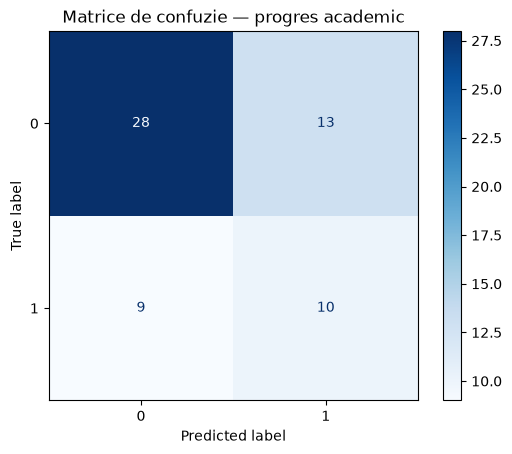

In [13]:
print('Accuracy:', round(accuracy_score(y_test_ac, pred_academic), 3))
print('Macro F1:', round(f1_score(y_test_ac, pred_academic, average='macro', zero_division=0), 3))
print(classification_report(y_test_ac, pred_academic, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test_ac, pred_academic, cmap='Blues')
plt.title('Matrice de confuzie — progres academic')
plt.show()


## 12. Antrenăm modelul pentru progres motivațional


In [14]:
y_train_mot = work.loc[train_mask, 'Progres_motivational']
y_test_mot = work.loc[~train_mask, 'Progres_motivational']
model_motivational = construieste_model()
model_motivational.fit(X_train, y_train_mot)
pred_motivational = model_motivational.predict(X_test)
print('Model motivațional antrenat.')


Model motivațional antrenat.


## 13. Evaluăm progresul motivațional


Accuracy: 0.567
Macro F1: 0.566
              precision    recall  f1-score   support

           0       0.56      0.60      0.58        30
           1       0.57      0.53      0.55        30

    accuracy                           0.57        60
   macro avg       0.57      0.57      0.57        60
weighted avg       0.57      0.57      0.57        60



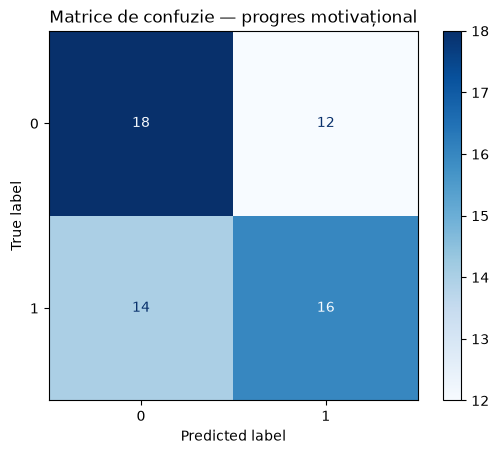

In [15]:
print('Accuracy:', round(accuracy_score(y_test_mot, pred_motivational), 3))
print('Macro F1:', round(f1_score(y_test_mot, pred_motivational, average='macro', zero_division=0), 3))
print(classification_report(y_test_mot, pred_motivational, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test_mot, pred_motivational, cmap='Blues')
plt.title('Matrice de confuzie — progres motivațional')
plt.show()


## 14. Comparăm Random Forest cu un model de bază


In [16]:
rezultate = []
for nume, y_tr, y_te, pred in [
    ('Academic', y_train_ac, y_test_ac, pred_academic),
    ('Motivațional', y_train_mot, y_test_mot, pred_motivational)
]:
    baseline = DummyClassifier(strategy='most_frequent')
    baseline.fit(X_train, y_tr)
    pred_base = baseline.predict(X_test)
    for model_name, yp in [('Dummy', pred_base), ('Random Forest', pred)]:
        rezultate.append({'Țintă': nume, 'Model': model_name,
                          'Accuracy': accuracy_score(y_te, yp),
                          'Macro F1': f1_score(y_te, yp, average='macro', zero_division=0)})
rezultate_df = pd.DataFrame(rezultate)
display(rezultate_df.round(3))


,Țintă,Model,Accuracy,Macro F1
0,Academic,Dummy,0.683,0.406
1,Academic,Random Forest,0.633,0.597
2,Motivațional,Dummy,0.500,0.333
3,Motivațional,Random Forest,0.567,0.566


## 15. Vizualizăm importanța caracteristicilor


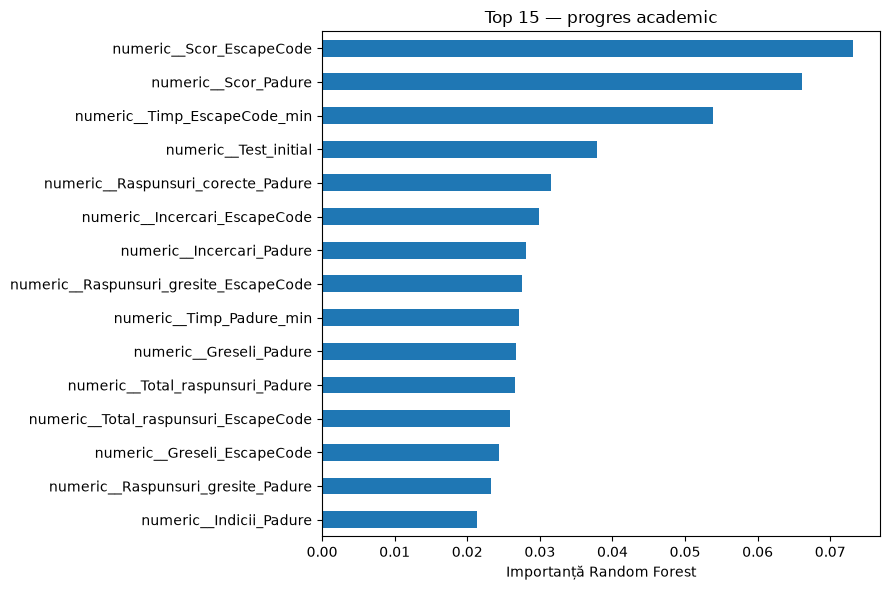

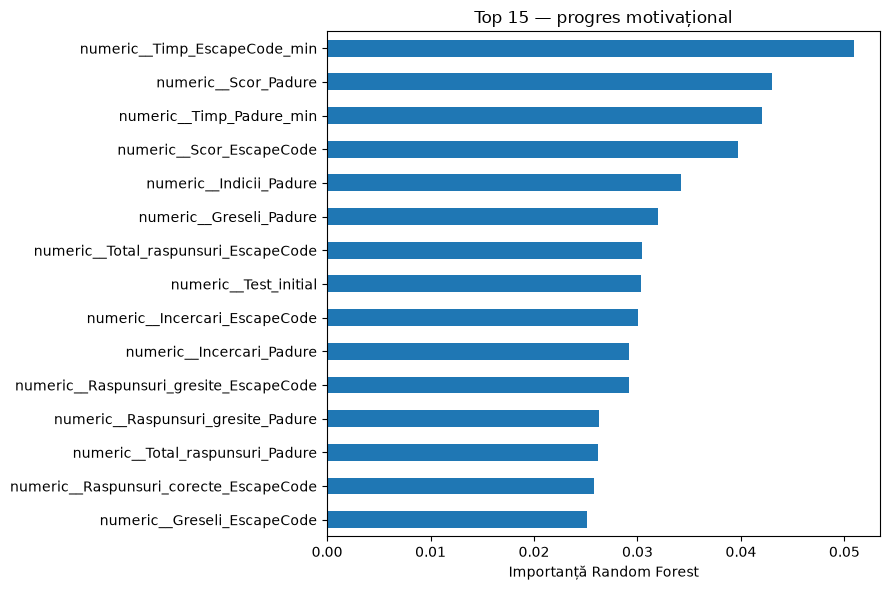

In [17]:
def grafic_importante(model, titlu):
    prep = model.named_steps['preprocesare']
    nume = prep.get_feature_names_out()
    importante = pd.Series(model.named_steps['random_forest'].feature_importances_, index=nume)
    importante.nlargest(15).sort_values().plot(kind='barh', figsize=(9, 6))
    plt.title(titlu)
    plt.xlabel('Importanță Random Forest')
    plt.tight_layout()
    plt.show()

grafic_importante(model_academic, 'Top 15 — progres academic')
grafic_importante(model_motivational, 'Top 15 — progres motivațional')


## 16. Salvăm rezultatele pe setul de test


In [18]:
rezultate_test = work.loc[~train_mask, ['StudentID'] + targets].copy()
rezultate_test['Predictie_academica'] = pred_academic
rezultate_test['Predictie_motivationala'] = pred_motivational
rezultate_test.to_csv('EduQuest_predictii_test.csv', index=False, encoding='utf-8-sig')
print('Salvat: EduQuest_predictii_test.csv')
display(rezultate_test.head())


Salvat: EduQuest_predictii_test.csv


,StudentID,Progres_academic,Progres_motivational,Predictie_academica,Predictie_motivationala
5,6,0,0,0,0
7,8,0,1,1,1
9,10,0,1,1,0
17,18,0,1,0,1
24,25,0,0,1,0


### Notă metodologică
